# Projeto 2: Preço e nota dos restaurantes do Zomato

## Etapa 1: Definir a pergunta

**Pergunta:** Restaurantes mais caros têm notas melhores?

**Colunas usadas:**
- `Aggregate rating`: nota do restaurante, de 0 a 5
- `Price range`: faixa de preço, de 1 (mais barato) a 4 (mais caro)

**Filtro:** só restaurantes com nota maior que 0, porque nota 0 significa "sem avaliação".

**Observação:** `Price range` é uma escala relativa. Um restaurante "faixa 4" na Índia e um "faixa 4" no Brasil não custam o mesmo valor.

## Etapa 2: Carregar e conhecer os dados

Carrego o arquivo e olho o tamanho, as colunas e os tipos, sem alterar nada.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/Zomato Restaurant Dataset.csv", encoding="utf-8-sig")

In [ ]:
df.shape

(9551, 21)

In [ ]:
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [ ]:
df[["Aggregate rating", "Price range"]].describe()

,Aggregate rating,Price range
count,9551.000000,9551.000000
mean,2.666370,1.804837
std,1.516378,0.905609
min,0.000000,1.000000
25%,2.500000,1.000000
50%,3.200000,2.000000
75%,3.700000,2.000000
max,4.900000,4.000000


In [ ]:
df["Price range"].value_counts().sort_index()

,count
Price range,
1,4444
2,3113
3,1408
4,586


O dataset tem 9.551 restaurantes e 21 colunas. As duas colunas da minha pergunta não têm valores vazios. A faixa de preço vai de 1 a 4, e a maioria dos restaurantes está nas faixas mais baratas (1 e 2).

## Etapa 3: Limpeza dos dados

Verifico valores vazios, duplicados, tipos e categorias, e removo os restaurantes sem avaliação.

In [ ]:
df.isna().sum()

,0
Restaurant ID,0
Restaurant Name,0
Country Code,0
City,0
Address,0
Locality,0
Locality Verbose,0
Longitude,0
Latitude,0
Cuisines,9


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["Price range"].value_counts().sort_index()

,count
Price range,
1,4444
2,3113
3,1408
4,586


In [ ]:
df[df["Aggregate rating"] == 0]["Rating text"].value_counts()

,count
Rating text,
Not rated,2148


In [ ]:
df_limpo = df[df["Aggregate rating"] > 0].copy()

print("Antes:", df.shape[0])
print("Depois:", df_limpo.shape[0])

Antes: 9551
Depois: 7403


In [ ]:
df_limpo["Price range"].value_counts().sort_index()

,count
Price range,
1,2744
2,2711
3,1373
4,575


Encontrei 9 restaurantes sem tipo de cozinha, que mantive porque a coluna não faz parte da pergunta. Não há duplicados e a faixa de preço só tem os valores 1 a 4. Removi os 2.148 restaurantes sem avaliação (nota 0), ficando com 7.403. Depois da remoção, as faixas ficaram com 2.744, 2.711, 1.373 e 575 restaurantes, e a faixa 1 foi a que mais perdeu restaurantes.

## Etapa 4: Análise exploratória

Olho a distribuição da nota, procuro outliers e confiro o tamanho de cada faixa de preço.

In [ ]:
df_limpo["Aggregate rating"].describe()

,Aggregate rating
count,7403.000000
mean,3.440024
std,0.552195
min,1.800000
25%,3.000000
50%,3.400000
75%,3.800000
max,4.900000


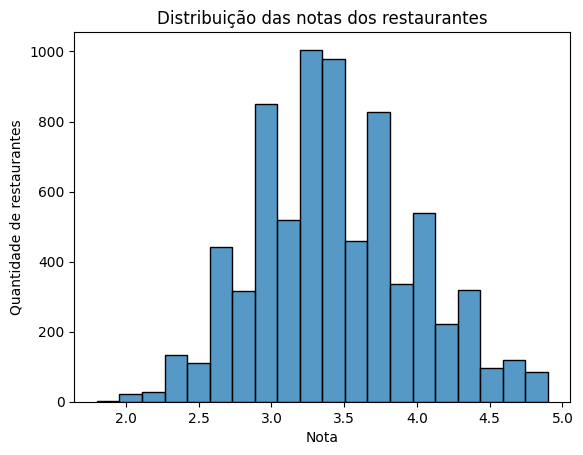

In [ ]:
sns.histplot(df_limpo["Aggregate rating"], bins=20)
plt.title("Distribuição das notas dos restaurantes")
plt.xlabel("Nota")
plt.ylabel("Quantidade de restaurantes")
plt.show()

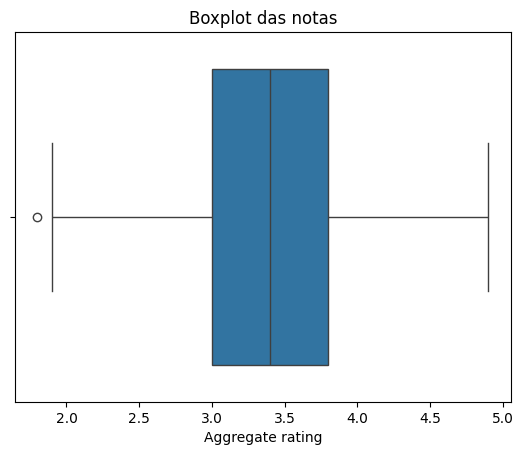

In [ ]:
sns.boxplot(x=df_limpo["Aggregate rating"])
plt.title("Boxplot das notas")
plt.show()

In [ ]:
contagem = df_limpo["Price range"].value_counts().sort_index()
porcentagem = (df_limpo["Price range"].value_counts(normalize=True).sort_index() * 100).round(1)

pd.DataFrame({"Restaurantes": contagem, "Porcentagem": porcentagem})

,Restaurantes,Porcentagem
Price range,,
1,2744,37.1
2,2711,36.6
3,1373,18.5
4,575,7.8


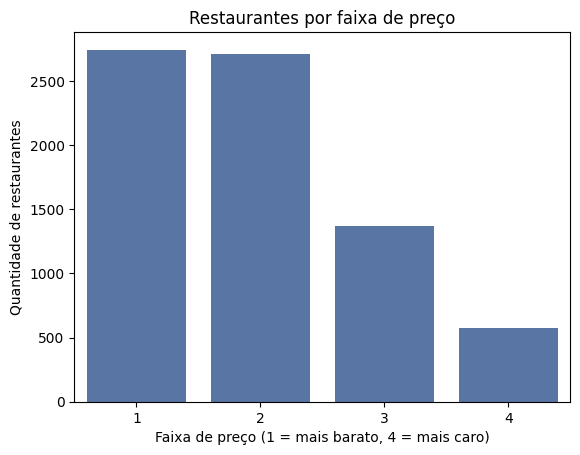

In [ ]:
sns.countplot(data=df_limpo, x="Price range", color="#4C72B0")
plt.title("Restaurantes por faixa de preço")
plt.xlabel("Faixa de preço (1 = mais barato, 4 = mais caro)")
plt.ylabel("Quantidade de restaurantes")
plt.show()

## Etapa 5: Comparar as faixas de preço

Comparo a nota dos restaurantes entre as 4 faixas de preço.

In [ ]:
df_limpo.groupby("Price range")["Aggregate rating"].agg(["count", "mean", "median", "std"]).round(3)

,count,mean,median,std
Price range,,,,
1,2744,3.239,3.2,0.444
2,2711,3.377,3.4,0.534
3,1373,3.777,3.8,0.535
4,575,3.891,3.9,0.523


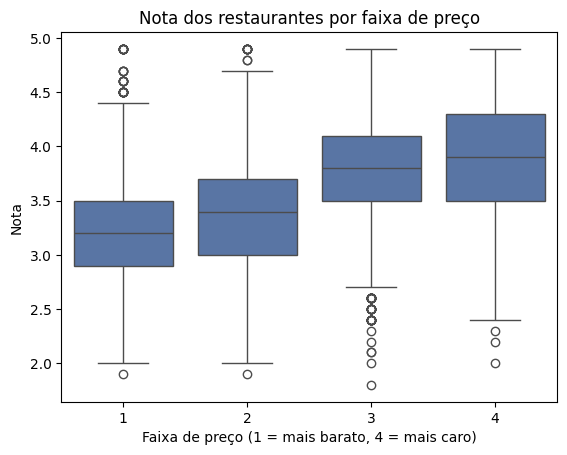

In [ ]:
sns.boxplot(data=df_limpo, x="Price range", y="Aggregate rating", color="#4C72B0")
plt.title("Nota dos restaurantes por faixa de preço")
plt.xlabel("Faixa de preço (1 = mais barato, 4 = mais caro)")
plt.ylabel("Nota")
plt.show()

In [ ]:
medias = df_limpo.groupby("Price range")["Aggregate rating"].mean()
medias.diff().round(3)

,Aggregate rating
Price range,
1,NaN
2,0.138
3,0.400
4,0.114


In [ ]:
df_limpo["Price range"].corr(df_limpo["Aggregate rating"], method="spearman")

np.float64(0.401744688707492)

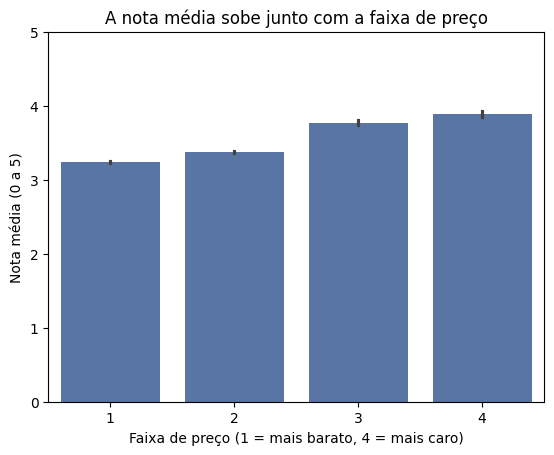

In [ ]:
ax = sns.barplot(data=df_limpo, x="Price range", y="Aggregate rating",
                 errorbar=("ci", 95), color="#4C72B0")
ax.set_ylim(0, 5)
ax.set_xlabel("Faixa de preço (1 = mais barato, 4 = mais caro)")
ax.set_ylabel("Nota média (0 a 5)")
ax.set_title("A nota média sobe junto com a faixa de preço")
plt.show()

A nota média sobe a cada faixa de preço: 3,24 na faixa 1, 3,38 na faixa 2, 3,78 na faixa 3 e 3,89 na faixa 4. O maior salto acontece entre as faixas 2 e 3 (+0,40). A correlação de Spearman entre preço e nota é de cerca de 0,40, uma relação positiva moderada. Preciso testar se essa diferença entre as faixas é estatisticamente real.

## Etapa 6: Teste de hipótese

Testo se a nota média é diferente entre as 4 faixas de preço.

- **H0 (hipótese nula):** a nota média é igual nas 4 faixas.
- **H1 (hipótese alternativa):** pelo menos uma faixa tem nota média diferente das outras.

In [ ]:
from scipy import stats

grupos = [df_limpo[df_limpo["Price range"] == faixa]["Aggregate rating"] for faixa in [1, 2, 3, 4]]

In [ ]:
F, p = stats.f_oneway(*grupos)

print(f"Estatística F: {F:.1f}")
print(f"p-valor: {p:.2e}")

Estatística F: 522.9
p-valor: 3.34e-308


In [ ]:
H, p_kw = stats.kruskal(*grupos)
print(f"p-valor (Kruskal-Wallis): {p_kw:.2e}")

p-valor (Kruskal-Wallis): 3.25e-287


In [ ]:
media_geral = df_limpo["Aggregate rating"].mean()
ss_entre = sum(len(g) * (g.mean() - media_geral) ** 2 for g in grupos)
ss_total = ((df_limpo["Aggregate rating"] - media_geral) ** 2).sum()

eta2 = ss_entre / ss_total
print(f"Eta ao quadrado: {eta2:.3f}")

Eta ao quadrado: 0.175


In [ ]:
from itertools import combinations

res = stats.tukey_hsd(*grupos)

for i, j in combinations(range(4), 2):
    dif = grupos[j].mean() - grupos[i].mean()
    print(f"Faixa {i+1} vs {j+1}: diferença {dif:.3f}, p = {res.pvalue[i, j]:.5f}")

Faixa 1 vs 2: diferença 0.138, p = 0.00000
Faixa 1 vs 3: diferença 0.538, p = 0.00000
Faixa 1 vs 4: diferença 0.652, p = 0.00000
Faixa 2 vs 3: diferença 0.400, p = 0.00000
Faixa 2 vs 4: diferença 0.514, p = 0.00000
Faixa 3 vs 4: diferença 0.114, p = 0.00003


A ANOVA (F ≈ 523, p < 1e-300) e o Kruskal-Wallis (p ≈ 3e-287) rejeitam a hipótese nula: a nota média difere entre as faixas de preço. O eta ao quadrado é de aproximadamente 0,175, então a faixa de preço explica cerca de 17,5% da variação das notas, um efeito grande. O teste de Tukey mostra que todos os pares de faixas diferem significativamente, com o menor degrau entre as faixas 3 e 4 (0,114) e o maior entre 2 e 3 (0,400).

## Etapa 7: Conclusão

In [ ]:
df_limpo["Pais"] = np.where(df_limpo["Country Code"] == 1, "Índia", "Fora da Índia")

for pais, grupo in df_limpo.groupby("Pais"):
    corr = grupo["Price range"].corr(grupo["Aggregate rating"], method="spearman")
    print(f"{pais}: {len(grupo)} restaurantes, correlação = {corr:.3f}")
    print(grupo.groupby("Price range")["Aggregate rating"].mean().round(2))
    print()

Fora da Índia: 890 restaurantes, correlação = 0.201
Price range
1    3.98
2    4.00
3    4.14
4    4.19
Name: Aggregate rating, dtype: float64

Índia: 6513 restaurantes, correlação = 0.354
Price range
1    3.20
2    3.31
3    3.68
4    3.73
Name: Aggregate rating, dtype: float64



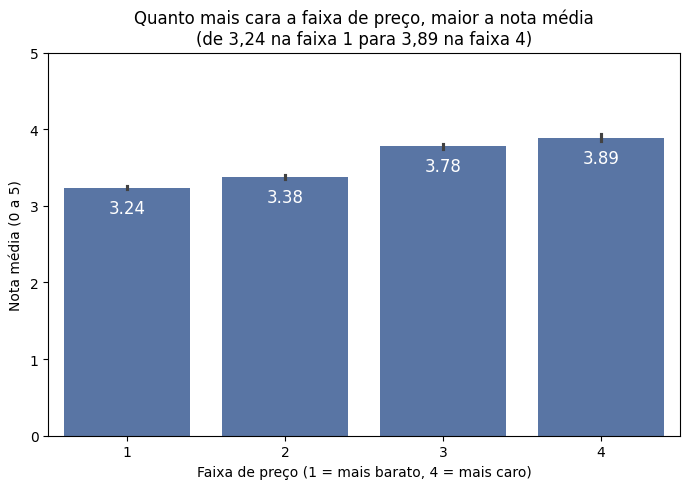

In [ ]:
medias = df_limpo.groupby("Price range")["Aggregate rating"].mean()

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    data=df_limpo,
    x="Price range",
    y="Aggregate rating",
    errorbar=("ci", 95),
    color="#4C72B0",
)

ax.set_ylim(0, 5)
ax.set_xlabel("Faixa de preço (1 = mais barato, 4 = mais caro)")
ax.set_ylabel("Nota média (0 a 5)")
ax.set_title("Quanto mais cara a faixa de preço, maior a nota média\n(de 3,24 na faixa 1 para 3,89 na faixa 4)")

for barra, valor in zip(ax.patches, medias):
    ax.annotate(
        f"{valor:.2f}",
        (barra.get_x() + barra.get_width() / 2, valor),
        xytext=(0, -18),
        textcoords="offset points",
        ha="center",
        color="white",
        fontsize=12,
    )

plt.tight_layout()
plt.savefig("grafico_final_preco.png", dpi=150)
plt.show()

## Conclusão

**Resposta:** Sim, restaurantes mais caros têm notas melhores. A nota média sobe a cada faixa de preço: 3,24 (faixa 1), 3,38 (faixa 2), 3,78 (faixa 3) e 3,89 (faixa 4), uma diferença de 0,65 pontos entre a mais barata e a mais cara.

**Evidência:** A ANOVA (F ≈ 523, p < 1e-300) e o Kruskal-Wallis (p ≈ 3e-287) indicam que a nota difere entre as faixas. O teste de Tukey mostra que todos os pares de faixas são diferentes entre si. O eta ao quadrado é cerca de 0,175, ou seja, a faixa de preço explica aproximadamente 17,5% da variação das notas, um efeito grande. A correlação de Spearman é de 0,40.

**Limites da análise:**
- Mostra associação, não causa: cobrar mais caro não faz a nota subir. Localização, tipo de cozinha e público não foram controlados.
- A faixa de preço é relativa a cada país, e 88% dos restaurantes avaliados são da Índia.
- A relação existe dentro da Índia (correlação 0,35) e fora dela (0,20), mas é mais fraca em cada grupo do que no conjunto, porque a mistura de países reforça o resultado geral.
- Removi os 2.148 restaurantes sem avaliação, e eles se concentram nas faixas baratas (a faixa 1 perdeu cerca de 38% dos restaurantes). Quem avalia restaurantes caros pode ser um público diferente.
- A faixa 4 tem só 575 restaurantes, então a média dela é menos estável.

**Próximos passos possíveis:** controlar o efeito do tipo de cozinha e da cidade, ou analisar a relação entre preço e nota separadamente para cada país com dados suficientes.